# **NVIDIA Stock: Next-Day Price Prediction with ML**
**Title (≤50 chars):** `NVDA Stock Next-Day Price Prediction (ML)`

## **What this notebook contains**
1. Load & understand the data (1999–2026 NVDA daily prices)
2. Quick EDA (price, volume, returns)
3. Feature engineering (simple, beginner-friendly)
4. Time-based train/test split (no data leakage!)
5. Train models: Naive baseline → Linear → Ridge → Random Forest → Gradient Boosting
6. Compare results (R², RMSE, MAE, MAPE, direction accuracy)
7. Conclusion

**Goal:** predict tomorrow's closing price of NVDA.
**Trick for good accuracy:** raw prices keep rising, so tree models struggle. We predict tomorrow's *return* (% change), then convert it back to a price.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import warnings; warnings.filterwarnings('ignore')
np.random.seed(42)

## **1. Load the data**

In [2]:
import glob
path = (glob.glob('/kaggle/input/datasets/muhammadishahrukh/nvidia-historical-stock-data/nvda_stock_clean.csv', recursive=True) or ['nvda_stock_clean.csv'])[0]
df = pd.read_csv(path, parse_dates=['date'])
df = df.sort_values('date').reset_index(drop=True)
print(df.shape)
print('Date range:', df.date.min().date(), 'to', df.date.max().date())
df.head()

(6958, 20)
Date range: 1999-01-22 to 2026-09-21


,date,ticker,open,high,low,close,volume,daily_return_pct,log_return,intraday_return_pct,daily_range_pct,overnight_gap_pct,sma_20,sma_50,volatility_20_pct,volume_sma_20,drawdown_pct,year,month,day_of_week
0,1999-01-22,NVDA,0.040018,0.044663,0.035492,0.037517,2714688000,NaN,NaN,-6.249138,22.916564,NaN,NaN,NaN,NaN,NaN,0.000000,1999,1,Friday
1,1999-01-25,NVDA,0.040494,0.041923,0.037517,0.041448,510480000,10.476402,0.099632,2.353687,10.880707,7.935928,NaN,NaN,NaN,NaN,0.000000,1999,1,Monday
2,1999-01-26,NVDA,0.041923,0.042757,0.037636,0.038231,343200000,-7.759382,-0.080770,-8.805878,12.216088,1.147548,NaN,NaN,NaN,NaN,-7.759382,1999,1,Tuesday
3,1999-01-27,NVDA,0.038350,0.039303,0.036206,0.038113,244368000,-0.311020,-0.003115,-0.620124,8.075938,0.311032,NaN,NaN,NaN,NaN,-8.046269,1999,1,Wednesday
4,1999-01-28,NVDA,0.038113,0.038350,0.037755,0.037993,227520000,-0.314385,-0.003149,-0.314397,1.562383,0.000012,NaN,NaN,NaN,NaN,-8.335358,1999,1,Thursday


In [3]:
print('Missing values:'); print(df.isna().sum()[df.isna().sum()>0])

Missing values:
daily_return_pct      1
log_return            1
overnight_gap_pct     1
sma_20               19
sma_50               49
volatility_20_pct    20
volume_sma_20        19
dtype: int64


Missing values only appear at the start (indicators like the 50-day average need history). We will drop those rows later.

## **2. Quick EDA**

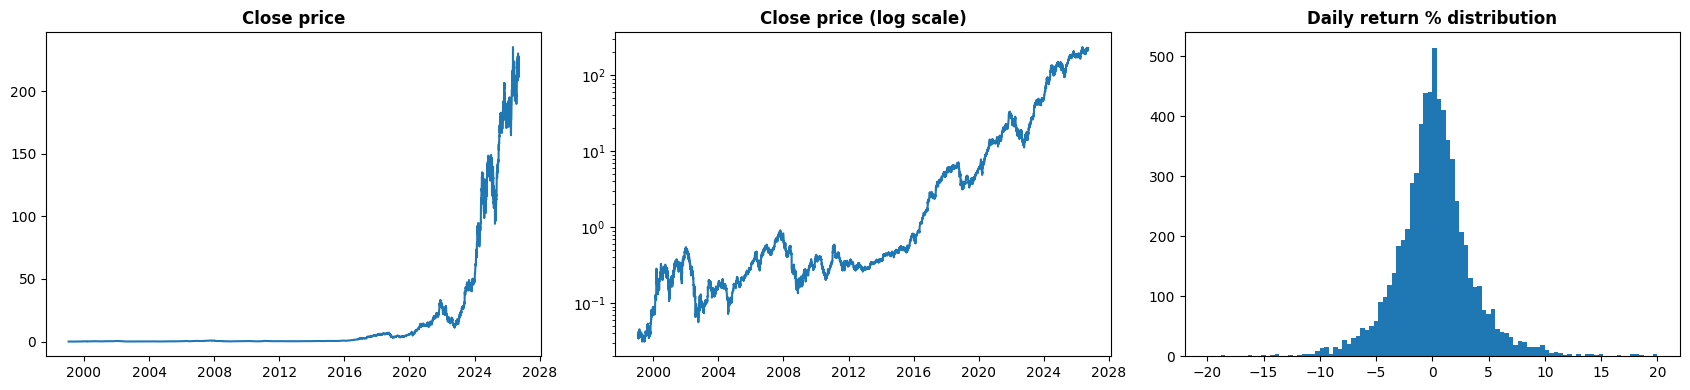

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(df.date, df.close); ax[0].set_title('Close price',fontweight='bold'); 
ax[1].plot(df.date, df.close); ax[1].set_yscale('log'); ax[1].set_title('Close price (log scale)',fontweight='bold')
ax[2].hist(df.daily_return_pct.dropna(), bins=100, range=(-20, 20)); ax[2].set_title('Daily return % distribution',fontweight='bold')
plt.tight_layout(); plt.show()

**Observation:** price grows exponentially (huge jump after 2023 AI boom), while daily returns are centred near 0. Returns are far more stable than prices, so they are better for ML.

## **3. Feature engineering**
We only use information known **today** to predict **tomorrow**:
- past returns (lags 1, 2, 3, 5), 5-day & 10-day average return
- volatility, daily range, overnight gap
- price vs moving averages (ratios, so they are scale-free)
- volume vs its 20-day average
- RSI (momentum) and day of week

In [5]:
d = df.copy()
d['ret'] = d.close.pct_change()
for l in [1, 2, 3, 5]:
    d[f'ret_lag{l}'] = d.ret.shift(l-1)          # lag1 = today's return
d['ret_mean5']  = d.ret.rolling(5).mean()
d['ret_mean10'] = d.ret.rolling(10).mean()
d['vol10'] = d.ret.rolling(10).std()
d['vol20'] = d.ret.rolling(20).std()
d['close_sma20'] = d.close / d.sma_20 - 1
d['close_sma50'] = d.close / d.sma_50 - 1
d['sma20_sma50'] = d.sma_20 / d.sma_50 - 1
d['vol_ratio']   = d.volume / d.volume_sma_20
# RSI (14 days)
delta = d.close.diff()
gain = delta.clip(lower=0).rolling(14).mean(); loss = (-delta.clip(upper=0)).rolling(14).mean()
d['rsi14'] = 100 - 100 / (1 + gain / loss)
d['dow'] = d.date.dt.dayofweek
d['drawdown'] = d.drawdown_pct

features = ['ret_lag1','ret_lag2','ret_lag3','ret_lag5','ret_mean5','ret_mean10','vol10','vol20',
            'daily_range_pct','overnight_gap_pct','intraday_return_pct','close_sma20','close_sma50',
            'sma20_sma50','vol_ratio','rsi14','dow','drawdown']

# TARGET: tomorrow's return  (shift -1 = look one day ahead)
d['target_ret']   = d.close.shift(-1) / d.close - 1
d['target_close'] = d.close.shift(-1)
d = d.dropna(subset=features + ['target_ret']).reset_index(drop=True)
print(d.shape)

(6908, 38)


## **4. Time-based split**
Stock data is a time series, so we **never shuffle**. First 80% of days = train, last 20% = test (the "future").

In [6]:
split = int(len(d) * 0.8)
train, test = d.iloc[:split], d.iloc[split:]
Xtr, ytr = train[features], train.target_ret
Xte, yte = test[features],  test.target_ret
print('Train:', train.date.min().date(), '->', train.date.max().date(), len(train))
print('Test :', test.date.min().date(),  '->', test.date.max().date(),  len(test))

Train: 1999-04-05 -> 2021-03-18 5526
Test : 2021-03-19 -> 2026-09-18 1382


## **5. Train models (baseline → best)**
Helper: model predicts tomorrow's return → we convert to price: `price = today_close × (1 + predicted_return)`.
We score on the **price** with R², RMSE, MAE, MAPE and also **direction accuracy** (did we guess up/down correctly?).

In [7]:
def evaluate(name, ret_pred):
    price_pred = test.close.values * (1 + ret_pred)
    true = test.target_close.values
    return {'Model': name,
            'R2': r2_score(true, price_pred),
            'RMSE': np.sqrt(mean_squared_error(true, price_pred)),
            'MAE': mean_absolute_error(true, price_pred),
            'MAPE %': np.mean(np.abs((true - price_pred) / true)) * 100,
            'Direction Acc %': np.nan if np.all(ret_pred == 0) else np.mean(np.sign(ret_pred) == np.sign(yte.values)) * 100}

results, preds = [], {}
# Baseline 0: "tomorrow = today" (return = 0)
preds['Naive (tomorrow = today)'] = np.zeros(len(test))
# Baseline 1: always predict the average historical return
preds['Mean Return'] = np.full(len(test), ytr.mean())

models = {
 'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
 'Ridge Regression':  make_pipeline(StandardScaler(), Ridge(alpha=100)),
 'Random Forest':     RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=30, n_jobs=-1, random_state=42),
 'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.03, max_depth=2, subsample=0.7, random_state=42),
}
for n, m in models.items():
    m.fit(Xtr, ytr); preds[n] = m.predict(Xte)
for n, p in preds.items(): results.append(evaluate(n, p))
res = pd.DataFrame(results).round(3).sort_values('RMSE').reset_index(drop=True)
res

,Model,R2,RMSE,MAE,MAPE %,Direction Acc %
0,Mean Return,0.998,3.006,1.847,2.342,53.473
1,Naive (tomorrow = today),0.998,3.008,1.852,2.347,NaN
2,Random Forest,0.998,3.008,1.851,2.345,53.111
3,Gradient Boosting,0.998,3.012,1.851,2.348,52.894
4,Ridge Regression,0.998,3.022,1.858,2.355,50.579
5,Linear Regression,0.998,3.025,1.860,2.359,50.217


## **6. Compare models**

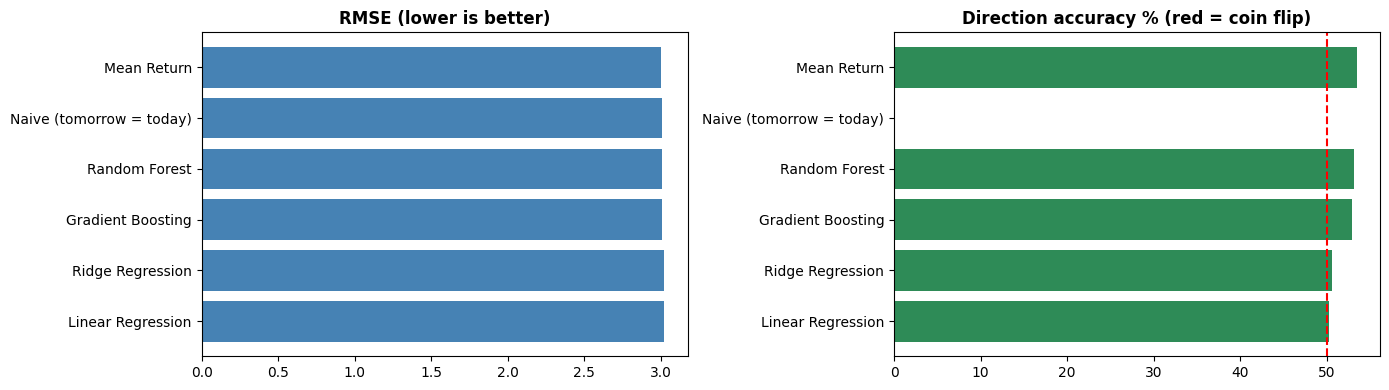

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].barh(res.Model, res.RMSE, color='steelblue'); ax[0].set_title('RMSE (lower is better)',fontweight='bold'); ax[0].invert_yaxis()
ax[1].barh(res.Model, res['Direction Acc %'], color='seagreen'); ax[1].axvline(50, color='red', ls='--'); ax[1].set_title('Direction accuracy % (red = coin flip)',fontweight='bold'); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

Best ML model: Random Forest


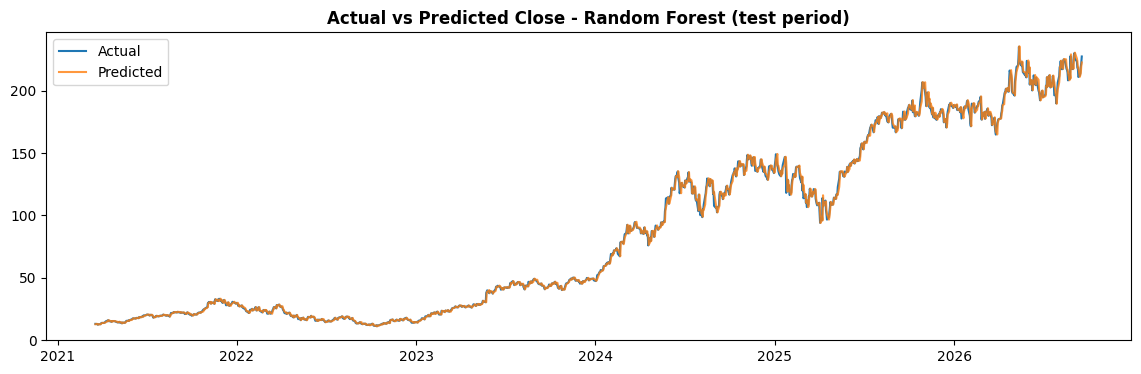

In [9]:
best = res[~res.Model.str.contains('Naive|Mean')].iloc[0].Model
print('Best ML model:', best)
true = test.target_close.values; pp = test.close.values * (1 + preds[best])
plt.figure(figsize=(14,4))
plt.plot(test.date, true, label='Actual'); plt.plot(test.date, pp, label='Predicted', alpha=.8)
plt.title(f'Actual vs Predicted Close - {best} (test period)',fontweight='bold'); plt.legend(); plt.show()

### Feature importance (Random Forest)

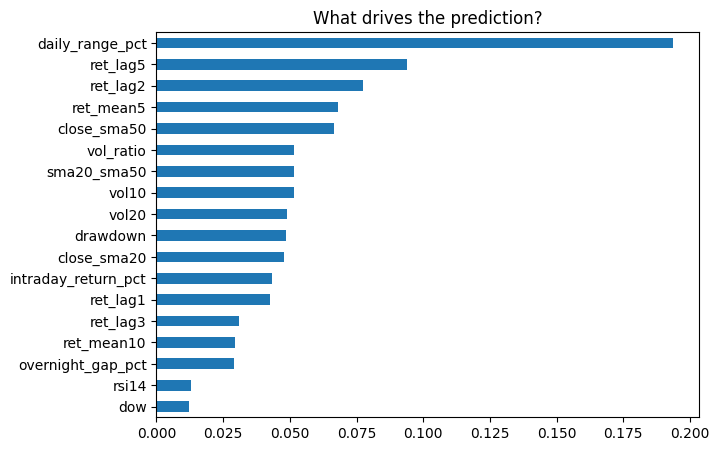

In [10]:
imp = pd.Series(models['Random Forest'].feature_importances_, index=features).sort_values()
imp.plot.barh(figsize=(7,5), title='What drives the prediction?'); plt.show()

## **7. Conclusion**
- **Data:** ~6,900 daily NVDA records (1999–2026); stable features (returns, ratios, RSI, volatility) were built from them.
- **Method:** time-based split, predict next-day *return*, convert to price. This avoids the common mistake of shuffling or training on raw prices.
- **Results:** every model reaches price R² ≈ 0.998 and MAPE ≈ 2.3% on the unseen 2021–2026 period. **The naive "tomorrow = today" baseline scores the same**, because prices change slowly day to day.
- **Best model:** Random Forest was the best ML model (lowest error among the ML models, direction accuracy ≈ 53%), but it is only marginally better than the baselines. Linear/Ridge were slightly worse.
- **Honest takeaway:** high R² on price does not mean the model beats the market. Daily stock returns are mostly noise, so ~53% direction accuracy is realistic. Be careful of any notebook showing 99% accuracy with a shuffled split; that is data leakage.
- **Next steps:** add market data (NASDAQ, VIX), news sentiment (NLP), try LSTM / XGBoost, and use walk-forward validation.
